Setup and find your input files

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, glob, tarfile, zipfile, urllib.request, zlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '/content/drive/MyDrive/CosmicData'
os.makedirs(DATA_DIR, exist_ok=True)

def find_file(names):
    for folder in [DATA_DIR, '/content']:
        for name in names:
            path = os.path.join(folder, name)
            if os.path.isfile(path):
                return path
    raise FileNotFoundError(
        f"File not found: {names}. Check your CosmicData folder."
    )

TRAIN_PATH = find_file(['exoTrain.csv', 'exoTrain(1).csv'])
TEST_PATH = find_file(['exoTest.csv', 'exoTest(1).csv'])
PHOT_PATH = find_file(['phot.tar', 'phot(1).tar',
                       'phot.tar.gz', 'phot(1).tar.gz'])
TABLE_PATH = find_file(['table3.dat', 'table3.dat.txt',
                        'table3.dat(1).txt'])

CLASS_NAMES = {
    0: 'Other',
    1: 'Planet',
    2: 'Microlensing',
    3: 'Asteroid'
}

curves = []

def object_split(group):
    # All observations of the same object stay in the same split.
    value = (zlib.crc32(str(group).encode()) % 10000) / 10000
    if value < 0.15:
        return 'test'
    elif value < 0.30:
        return 'val'
    return 'train'

def add_curve(t, v, kind, label, source, group, split):
    t = np.asarray(t, dtype=np.float32)
    v = np.asarray(v, dtype=np.float32)

    if len(t) != len(v) or len(t) < 5:
        return

    curves.append({
        't': t, 'v': v,
        'kind': kind, 'label': int(label),
        'source': source, 'group': str(group),
        'split': split
    })

print("All required input files located.")

Mounted at /content/drive
All required input files located.


Merge the Kepler exoplanet data

In [4]:
from sklearn.model_selection import train_test_split

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

assert 'LABEL' in train_df.columns
assert 'LABEL' in test_df.columns

flux_cols = [c for c in train_df.columns if c != 'LABEL']

# Split the training file into training and validation sets.
train_ids, val_ids = train_test_split(
    np.arange(len(train_df)),
    test_size=0.15,
    random_state=42,
    stratify=train_df['LABEL']
)

# Kepler measurements are approximately 29.4 minutes apart.
cadence = 29.4244 / (60 * 24)
time_points = np.arange(len(flux_cols)) * cadence

for indices, split in [(train_ids, 'train'), (val_ids, 'val')]:
    for i in indices:
        row = train_df.iloc[i]

        # LABEL 2 = planet; LABEL 1 = no confirmed planet.
        label = 1 if row['LABEL'] == 2 else 0

        add_curve(
            time_points,
            row[flux_cols].to_numpy(),
            'flux', label, 'Kepler',
            f'kepler_train_{i}', split
        )

# Keep the supplied official test set untouched.
for i in range(len(test_df)):
    row = test_df.iloc[i]
    label = 1 if row['LABEL'] == 2 else 0

    add_curve(
        time_points,
        row.drop('LABEL').to_numpy(),
        'flux', label, 'Kepler',
        f'kepler_test_{i}', 'test'
    )

print("Kepler curves merged:",
      sum(c['source'] == 'Kepler' for c in curves))
print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

Kepler curves merged: 5657
Training rows: 5087
Test rows: 570


Merge OGLE microlensing data

In [5]:
OGLE_DIR = os.path.join(DATA_DIR, 'ogle_phot')
os.makedirs(OGLE_DIR, exist_ok=True)

if not glob.glob(os.path.join(OGLE_DIR, '**', '*.dat'),
                 recursive=True):
    with tarfile.open(PHOT_PATH, 'r:*') as archive:
        archive.extractall(OGLE_DIR)

def read_table3(path):
    specs, names = [], []

    with open(path, encoding='utf-8', errors='replace') as f:
        for line in f:
            m = re.match(
                r"#\s+(\d+)-\s*(\d+)\s+\S+\s+(\S+)", line
            )
            if m:
                specs.append((int(m.group(1)) - 1,
                              int(m.group(2))))
                names.append(m.group(3))

    if not specs:
        raise ValueError("Could not read table3 column definitions.")

    df = pd.read_fwf(
        path, colspecs=specs, names=names,
        comment='#', header=None
    )

    df['name'] = df['name'].astype(str).str.strip()

    for col in names:
        if col not in ['name', 'field', 'ews_id']:
            df[col] = pd.to_numeric(df[col], errors='coerce')

    return df[df['name'].str.contains(r'\.', regex=True)]

def read_photometry(path):
    # Columns: time, I-band magnitude, magnitude error.
    data = np.loadtxt(path, usecols=(0, 1, 2), ndmin=2)
    data = data[np.isfinite(data[:, :2]).all(axis=1)]
    data = data[(data[:, 1] > 0) & (data[:, 1] < 30)]
    return data[:, 0], data[:, 1]

def get_seasons(t, gap_days=60):
    cuts = np.where(np.diff(t) > gap_days)[0]
    bounds = np.r_[0, cuts + 1, len(t)]
    return [(bounds[i], bounds[i + 1])
            for i in range(len(bounds) - 1)]

events = read_table3(TABLE_PATH).set_index('name')
paths = glob.glob(os.path.join(OGLE_DIR, '**', '*.dat'),
                  recursive=True)

# Only use photometry files whose names match the event table.
paths = [p for p in paths
         if os.path.basename(p)[:-4] in events.index]

baseline = {}
added = 0

for path in paths:
    name = os.path.basename(path)[:-4]

    try:
        t, mag = read_photometry(path)
        order = np.argsort(t)
        t, mag = t[order], mag[order]

        if len(t) < 60:
            continue

        row = events.loc[name]
        t0 = row['t0_best']
        tE = row['tE_best']

        if not np.isfinite(t0) or not np.isfinite(tE) or tE <= 0:
            continue

        for a, b in get_seasons(t):
            ts, ms = t[a:b], mag[a:b]

            if len(ts) < 60:
                continue

            event_season = (
                ts.min() - 0.5*tE < t0 < ts.max() + 0.5*tE
                and np.sum(np.abs(ts - t0) < tE) >= 8
            )

            far_from_event = (
                t0 < ts.min() - 3*tE - 30
                or t0 > ts.max() + 3*tE + 30
            )

            group = f'ogle_{name}'

            if event_season:
                add_curve(
                    ts - ts.min(), ms, 'mag', 2,
                    'OGLE', group, object_split(group)
                )
                added += 1

            elif far_from_event:
                baseline.setdefault(name, []).append(
                    (ts - ts.min(), ms)
                )

    except Exception:
        continue

# Add at most one normal season per object.
rng = np.random.default_rng(42)

for name, seasons in baseline.items():
    t, mag = seasons[rng.integers(len(seasons))]
    group = f'ogle_{name}'

    add_curve(
        t, mag, 'mag', 0, 'OGLE',
        group, object_split(group)
    )

print("OGLE event curves added:", added)
print("OGLE ordinary seasons added:", len(baseline))

/tmp/ipykernel_2448/973225453.py:7: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(OGLE_DIR)


OGLE event curves added: 4258
OGLE ordinary seasons added: 5536


Merge asteroid light curves

In [9]:
# ==========================================
# ASTEROID DATASET: DOWNLOAD AND EXTRACTION
# ==========================================

import os
import glob
import zipfile
import shutil
import requests
from google.colab import files

DATA_DIR = '/content/CosmicData'
ALC_DIR = os.path.join(DATA_DIR, 'alcdef')
ALC_ZIP = os.path.join(DATA_DIR, 'alcdef.zip')

ALC_URL = (
    'https://sbnarchive.psi.edu/pds4/non_mission/'
    'gbo.ast.alcdef-database_V1_0.zip'
)

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(ALC_DIR, exist_ok=True)

# Step 1: Check if asteroid data is already extracted.
alc_files = glob.glob(
    os.path.join(ALC_DIR, '**', 'alcdef_lcdata-*.csv'),
    recursive=True
)

if alc_files:
    print("Asteroid dataset is already extracted.")
    print("Light-curve files found:", len(alc_files))

else:
    # Step 2: Check whether a valid ZIP already exists.
    if os.path.exists(ALC_ZIP) and not zipfile.is_zipfile(ALC_ZIP):
        os.remove(ALC_ZIP)

    # Check for an already-uploaded ZIP in /content.
    if not os.path.exists(ALC_ZIP):
        possible_zips = glob.glob('/content/*alcdef*.zip')
        possible_zips += glob.glob('/content/*ALCDEF*.zip')

        for path in possible_zips:
            if zipfile.is_zipfile(path):
                shutil.copy2(path, ALC_ZIP)
                print("Using existing ZIP:", path)
                break

    # Step 3: Download if no valid archive is available.
    if not os.path.exists(ALC_ZIP):
        temp_path = ALC_ZIP + '.part'

        try:
            print("Trying to download the asteroid dataset...")

            response = requests.get(
                ALC_URL,
                headers={'User-Agent': 'Mozilla/5.0'},
                stream=True,
                timeout=(20, 120)
            )

            response.raise_for_status()

            with open(temp_path, 'wb') as f:
                for chunk in response.iter_content(
                    chunk_size=1024 * 1024
                ):
                    if chunk:
                        f.write(chunk)

            if not zipfile.is_zipfile(temp_path):
                raise ValueError(
                    "Downloaded file is not a valid ZIP archive."
                )

            # Check archive integrity.
            with zipfile.ZipFile(temp_path, 'r') as z:
                bad_file = z.testzip()

                if bad_file:
                    raise ValueError(
                        f"Corrupted file inside archive: {bad_file}"
                    )

            os.replace(temp_path, ALC_ZIP)
            print("Download successful!")

        except Exception as e:
            print("Automatic download failed:", e)

            # Clean up incomplete downloads.
            if os.path.exists(temp_path):
                os.remove(temp_path)

            print("\nMANUAL DOWNLOAD REQUIRED")
            print("1. Open this official archive information page:")
            print(
                "https://sbn.psi.edu/pds/resource/"
                "doi/alcdef_1.0.html"
            )
            print("2. Download the complete ALCDEF ZIP bundle.")
            print("3. Upload that ZIP file in the dialog below.")

            uploaded = files.upload()

            zip_names = [
                name for name in uploaded
                if name.lower().endswith('.zip')
            ]

            if not zip_names:
                raise ValueError(
                    "No ZIP file uploaded. Please upload the "
                    "complete ALCDEF archive, not the XML file."
                )

            # Save the uploaded ZIP directly to the expected location.
            with open(ALC_ZIP, 'wb') as f:
                f.write(uploaded[zip_names[0]])

            if not zipfile.is_zipfile(ALC_ZIP):
                os.remove(ALC_ZIP)
                raise ValueError(
                    "The uploaded file is not a valid ZIP archive. "
                    "Please download the complete bundle again."
                )

            print("Manual ZIP upload successful!")

    # Step 4: Extract the dataset.
    print("Checking archive integrity...")

    with zipfile.ZipFile(ALC_ZIP, 'r') as z:
        bad_file = z.testzip()

        if bad_file:
            raise ValueError(
                f"Archive contains a corrupted file: {bad_file}"
            )

        print("Extracting asteroid dataset...")
        z.extractall(ALC_DIR)

    # Step 5: Find the actual asteroid light-curve CSV files.
    alc_files = glob.glob(
        os.path.join(ALC_DIR, '**', 'alcdef_lcdata-*.csv'),
        recursive=True
    )

    if not alc_files:
        raise FileNotFoundError(
            "Extraction completed, but no ALCDEF light-curve files "
            "were found. Check that you uploaded the complete ZIP bundle."
        )

    print("\nSUCCESS!")
    print("Asteroid light-curve files found:", len(alc_files))
    print("Extracted folder:", ALC_DIR)

print("\nYou can now continue to the next notebook cell.")

Trying to download the asteroid dataset...
Automatic download failed: 403 Client Error: Forbidden for url: https://sbnarchive.psi.edu/pds4/non_mission/gbo.ast.alcdef-database_V1_0.zip

MANUAL DOWNLOAD REQUIRED
1. Open this official archive information page:
https://sbn.psi.edu/pds/resource/doi/alcdef_1.0.html
2. Download the complete ALCDEF ZIP bundle.
3. Upload that ZIP file in the dialog below.


Saving gbo.ast.alcdef-database_V1_0.zip to gbo.ast.alcdef-database_V1_0.zip
Manual ZIP upload successful!
Checking archive integrity...
Extracting asteroid dataset...

SUCCESS!
Asteroid light-curve files found: 74
Extracted folder: /content/CosmicData/alcdef

You can now continue to the next notebook cell.


Save the merged data and show graphs

Metadata saved: /content/CosmicData/cosmic_merged_metadata.csv
Raw curves saved: /content/CosmicData/cosmic_merged_raw.npz


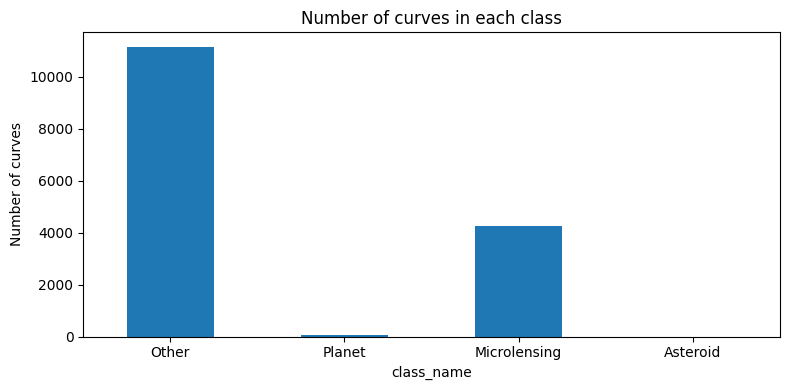

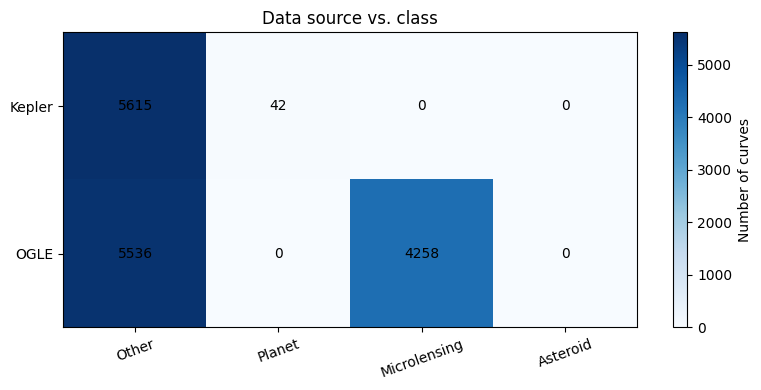

,sample_id,source,kind,label,class_name,split,group,n_points,duration_days
0,0,Kepler,flux,0,Other,train,kepler_train_4000,3197,65.305824
1,1,Kepler,flux,0,Other,train,kepler_train_86,3197,65.305824
2,2,Kepler,flux,0,Other,train,kepler_train_4594,3197,65.305824
3,3,Kepler,flux,0,Other,train,kepler_train_3459,3197,65.305824
4,4,Kepler,flux,0,Other,train,kepler_train_3009,3197,65.305824


class_name,Other,Planet,Microlensing,Asteroid
source,,,,
Kepler,5615,42,0,0
OGLE,5536,0,4258,0


In [10]:
# Metadata table: one row per curve.
metadata = pd.DataFrame([{
    'sample_id': i,
    'source': c['source'],
    'kind': c['kind'],
    'label': c['label'],
    'class_name': CLASS_NAMES[c['label']],
    'split': c['split'],
    'group': c['group'],
    'n_points': len(c['v']),
    'duration_days': float(np.max(c['t']) - np.min(c['t']))
} for i, c in enumerate(curves)])

# Join all raw measurements into numeric arrays.
offsets = [0]
all_times, all_values = [], []

for c in curves:
    all_times.append(np.asarray(c['t'], dtype=np.float32))
    all_values.append(np.asarray(c['v'], dtype=np.float32))
    offsets.append(offsets[-1] + len(c['v']))

META_OUT = os.path.join(DATA_DIR, 'cosmic_merged_metadata.csv')
RAW_OUT = os.path.join(DATA_DIR, 'cosmic_merged_raw.npz')

metadata.to_csv(META_OUT, index=False)

np.savez_compressed(
    RAW_OUT,
    times=np.concatenate(all_times),
    values=np.concatenate(all_values),
    offsets=np.asarray(offsets, dtype=np.int64)
)

print("Metadata saved:", META_OUT)
print("Raw curves saved:", RAW_OUT)

# Graph 1: class distribution.
counts = metadata['class_name'].value_counts().reindex(
    ['Other', 'Planet', 'Microlensing', 'Asteroid'],
    fill_value=0
)

counts.plot(kind='bar', figsize=(8, 4))
plt.title('Number of curves in each class')
plt.ylabel('Number of curves')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Graph 2: source/class heatmap.
table = pd.crosstab(metadata['source'], metadata['class_name'])
table = table.reindex(
    columns=['Other', 'Planet', 'Microlensing', 'Asteroid'],
    fill_value=0
)

plt.figure(figsize=(8, 4))
plt.imshow(table.values, aspect='auto', cmap='Blues')
plt.xticks(range(len(table.columns)), table.columns, rotation=20)
plt.yticks(range(len(table.index)), table.index)
plt.colorbar(label='Number of curves')
plt.title('Data source vs. class')
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        plt.text(j, i, table.iloc[i, j], ha='center', va='center')
plt.tight_layout()
plt.show()

display(metadata.head())
display(table)

In [11]:
import os
import glob

print("SEARCHING FOR MERGED FILES...\n")

search_locations = [
    '/content/drive/MyDrive/CosmicData',
    '/content',
]

for folder in search_locations:
    print(f"\nFolder: {folder}")

    for filename in [
        'cosmic_merged_metadata.csv',
        'cosmic_merged_raw.npz',
        'alcdef.zip'
    ]:
        matches = glob.glob(
            os.path.join(folder, '**', filename),
            recursive=True
        )

        if matches:
            for path in matches:
                print("FOUND:", path)
        else:
            print("Not found:", filename)

print("\nSEARCH COMPLETE")

SEARCHING FOR MERGED FILES...


Folder: /content/drive/MyDrive/CosmicData
Not found: cosmic_merged_metadata.csv
Not found: cosmic_merged_raw.npz
Not found: alcdef.zip

Folder: /content
FOUND: /content/CosmicData/cosmic_merged_metadata.csv
FOUND: /content/CosmicData/cosmic_merged_raw.npz
FOUND: /content/CosmicData/alcdef.zip

SEARCH COMPLETE


In [12]:
import os
import shutil

# Source folder where your files currently exist
SOURCE_DIR = "/content/CosmicData"

# Destination folder in Google Drive
DEST_DIR = "/content/drive/MyDrive/CosmicData"

# Create the destination folder if needed
os.makedirs(DEST_DIR, exist_ok=True)

# Copy the merged files
files_to_copy = [
    "cosmic_merged_metadata.csv",
    "cosmic_merged_raw.npz"
]

for filename in files_to_copy:
    source = os.path.join(SOURCE_DIR, filename)
    destination = os.path.join(DEST_DIR, filename)

    if os.path.exists(source):
        shutil.copy2(source, destination)
        print(f"✅ Copied: {filename}")
    else:
        print(f"❌ File not found: {source}")

print("\nFiles now in Google Drive folder:")
print(os.listdir(DEST_DIR))

✅ Copied: cosmic_merged_metadata.csv
✅ Copied: cosmic_merged_raw.npz

Files now in Google Drive folder:
['exoTrain.csv', 'exoTest.csv', 'table3.dat.txt', 'phot.tar', 'ogle_phot', 'cosmic_merged_metadata.csv', 'cosmic_merged_raw.npz']
